Sample Wireless Sensor Network Dataset:
            Timestamp      Source_IP         Event_Type  Packet_Size  \
0 2026-01-01 00:00:00  192.168.1.103  Data_Transmission         1301   
1 2026-01-01 01:00:00  192.168.1.180       Sensor_Alert          645   
2 2026-01-01 02:00:00   192.168.1.93     Routing_Update          299   
3 2026-01-01 03:00:00   192.168.1.15     Routing_Update          924   
4 2026-01-01 04:00:00  192.168.1.107      Login_Attempt          245   

   Transmission_Rate  Failed_Attempts  Signal_Strength  Malicious  
0                 76                5               32          0  
1                 22                9               84          0  
2                 86                0               39          0  
3                 47                3               76          0  
4                 81                0               65          0  

Training Samples: 1600
Testing Samples: 400

Random Forest Model Trained Successfully!

Model Accuracy: 85.25%

Classi

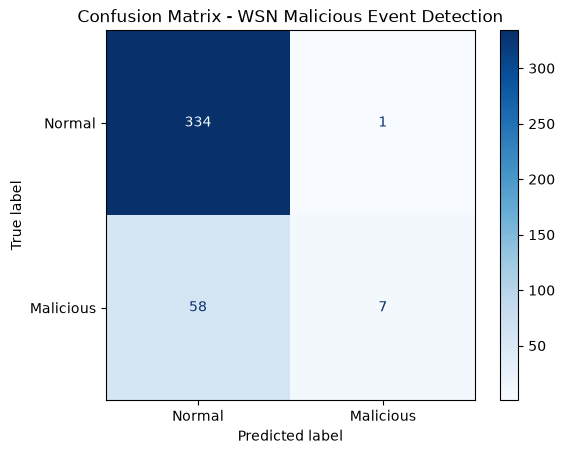


Feature Importance:
              Feature  Importance
5         Packet_Size    0.262447
6   Transmission_Rate    0.171392
8     Signal_Strength    0.145806
7     Failed_Attempts    0.140024
3   Source_IP_Encoded    0.063589
4  Event_Type_Encoded    0.063200
0                Hour    0.061153
1                 Day    0.060281
2         Day_Of_Week    0.032109


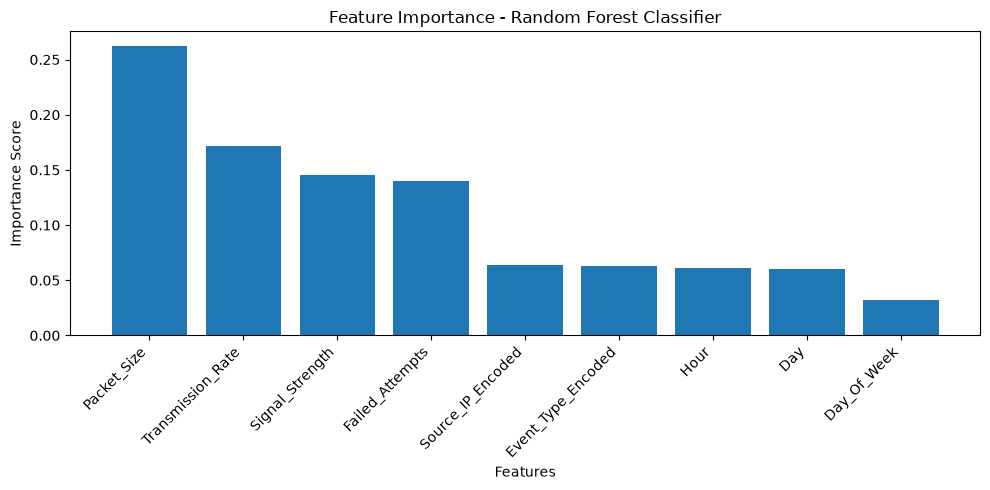


New Wireless Sensor Network Event Analysis:
ALERT: Malicious Network Event Detected!

Prediction Probabilities:
Normal Event: 21.99%
Malicious Event: 78.01%

Experiment Completed Successfully!


In [2]:
# Experiment 12:Develop a model that uses context(e.g:timestamp, source IP, and event type)to detect malicious events within wireless sensor networks.

# Experiment: Malicious Event Detection in Wireless Sensor Networks
# Using Random Forest Classifier
# Machine Learning for Cybersecurity

# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Step 2: Generate a simulated Wireless Sensor Network dataset

np.random.seed(42)

n_samples = 2000

# Generate timestamps
timestamps = pd.date_range(
    start='2026-01-01',
    periods=n_samples,
    freq='h'
)

# Generate source IP addresses
source_ips = [
    f"192.168.1.{np.random.randint(1, 255)}"
    for i in range(n_samples)
]

# Generate event types
event_types = np.random.choice(
    ['Data_Transmission', 'Login_Attempt',
     'Routing_Update', 'Sensor_Alert'],
    n_samples
)

# Generate network activity features
data = pd.DataFrame({
    'Timestamp': timestamps,
    'Source_IP': source_ips,
    'Event_Type': event_types,
    'Packet_Size': np.random.randint(50, 1500, n_samples),
    'Transmission_Rate': np.random.randint(1, 100, n_samples),
    'Failed_Attempts': np.random.randint(0, 10, n_samples),
    'Signal_Strength': np.random.randint(20, 100, n_samples)
})

# Step 3: Create target labels
# 0 = Normal Event
# 1 = Malicious Event

risk_score = (
    (data['Failed_Attempts'] > 6).astype(int) +
    (data['Transmission_Rate'] > 80).astype(int) +
    (data['Packet_Size'] > 1200).astype(int) +
    (data['Signal_Strength'] < 35).astype(int) +
    (data['Event_Type'] == 'Routing_Update').astype(int)
)

data['Malicious'] = (risk_score >= 3).astype(int)

# Introduce 10% label noise to simulate realistic variations

noise = np.random.choice(
    [0, 1],
    size=n_samples,
    p=[0.90, 0.10]
)

data['Malicious'] = np.where(
    noise == 1,
    1 - data['Malicious'],
    data['Malicious']
)

# Display sample records

print("Sample Wireless Sensor Network Dataset:")
print(data.head())

# Step 4: Extract timestamp information

data['Hour'] = data['Timestamp'].dt.hour
data['Day'] = data['Timestamp'].dt.day
data['Day_Of_Week'] = data['Timestamp'].dt.dayofweek

# Step 5: Encode categorical features

ip_encoder = LabelEncoder()
event_encoder = LabelEncoder()

data['Source_IP_Encoded'] = ip_encoder.fit_transform(
    data['Source_IP']
)

data['Event_Type_Encoded'] = event_encoder.fit_transform(
    data['Event_Type']
)

# Step 6: Select input features and target variable

X = data[[
    'Hour',
    'Day',
    'Day_Of_Week',
    'Source_IP_Encoded',
    'Event_Type_Encoded',
    'Packet_Size',
    'Transmission_Rate',
    'Failed_Attempts',
    'Signal_Strength'
]]

y = data['Malicious']

# Step 7: Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

# Step 8: Create and train Random Forest Classifier

model = RandomForestClassifier(
    n_estimators=100,
    max_depth=7,
    min_samples_split=15,
    min_samples_leaf=5,
    random_state=42
)

model.fit(X_train, y_train)

print("\nRandom Forest Model Trained Successfully!")

# Step 9: Predict malicious events

y_pred = model.predict(X_test)

# Step 10: Calculate model accuracy

accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy: {:.2f}%".format(accuracy * 100))

# Step 11: Display classification report

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    target_names=['Normal Event', 'Malicious Event']
))

# Step 12: Display confusion matrix

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Normal', 'Malicious']
)

disp.plot(cmap='Blues')

plt.title('Confusion Matrix - WSN Malicious Event Detection')
plt.show()

# Step 13: Display feature importance

importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print("\nFeature Importance:")
print(importance)

plt.figure(figsize=(10, 5))

plt.bar(
    importance['Feature'],
    importance['Importance']
)

plt.xlabel('Features')
plt.ylabel('Importance Score')
plt.title('Feature Importance - Random Forest Classifier')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Step 14: Test the model with a new network event

new_event = pd.DataFrame({
    'Hour': [2],
    'Day': [15],
    'Day_Of_Week': [3],
    'Source_IP_Encoded': [
        ip_encoder.transform(['192.168.1.100'])[0]
    ],
    'Event_Type_Encoded': [
        event_encoder.transform(['Routing_Update'])[0]
    ],
    'Packet_Size': [1450],
    'Transmission_Rate': [95],
    'Failed_Attempts': [8],
    'Signal_Strength': [25]
})

prediction = model.predict(new_event)

probability = model.predict_proba(new_event)

print("\nNew Wireless Sensor Network Event Analysis:")

if prediction[0] == 1:
    print("ALERT: Malicious Network Event Detected!")
else:
    print("SAFE: Normal Network Event Detected.")

print("\nPrediction Probabilities:")
print("Normal Event: {:.2f}%".format(
    probability[0][0] * 100
))

print("Malicious Event: {:.2f}%".format(
    probability[0][1] * 100
))

# Step 15: Experiment completed

print("\nExperiment Completed Successfully!")

